# Quiz 4 - Programming Excercises

In this exercise, you will implement and compare the performance of the SVM Primal and Dual methods presented in the lecture about the “Support Vector Machine”.

The code below prepares the data required for this exercise.

In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer

# Load the data
X, y = load_breast_cancer(return_X_y=True)  # X input, y output
print(X.shape, y.shape)
# to convert the {0,1} output into {-1,+1}
y = 2 * y - 1

mdata, ndim = X.shape  # size of the data

# scale the input data
X /= np.outer(np.ones(mdata), np.max(np.abs(X), 0))

print("new X", X)

(569, 30) (569,)
new X [[0.63998577 0.26425662 0.65145889 ... 0.91202749 0.69313046 0.57301205]
 [0.73176805 0.45239308 0.70503979 ... 0.63917526 0.41428141 0.42901205]
 [0.70046247 0.54098778 0.68965517 ... 0.83505155 0.54429045 0.42207229]
 ...
 [0.59053718 0.71486762 0.57453581 ... 0.48728522 0.33413679 0.37686747]
 [0.73283529 0.74669043 0.74323607 ... 0.91065292 0.6156975  0.59759036]
 [0.27605834 0.62474542 0.25421751 ... 0.         0.43250979 0.33922892]]


**Task 1a**: Complete the `svm_primal_cls` class below to implement the SVM Primal method.

In [3]:
class svm_primal_cls:

    def __init__(self, C=1000, eta=0.1, xlambda=0.01, nitermax=10):

        self.C = C                 ## penalty constant
        self.eta = eta             ## learning rate for the primal method
        self.nitermax = nitermax   ## maximum number of iterations
        self.xlambda = xlambda     ## lambda  = 1/C
        self.w = None              ## weight vector

        return

    # ---------------------------------------------------------
    def fit(self, X, y):
        """
        Task: to solve the support Vector Machine
              by applying stochastic gradient descent method
        Input:  X      2d array of input examples in the rows
                y      1d(vector) array of +1,-1 labels
        """
        m, n = X.shape

        # initialize the primal variables
        w = np.zeros(n)

        # iteration on the full training data
        for t in range(self.nitermax):
            # process all sample examples sequentially
            for i in range(m):
              # TODO: Stochastic gradient descent algorithm for SVM

              margin = y[i] * np.dot(w,X[i])
              if margin < 1: 
                w = w - self.eta * (self.xlambda * w - y[i] * X[i])
              else:
                w = w - self.eta * self.xlambda * w
        self.w = w
        return

    # ------------------------------------------
    def predict(self, Xtest):
        """
        Task: to predict the labels for the given examples based on the self.w
        Input:  Xtest   2d array of input examples in the rows
        Output: y       1d array of predicted labels
        """
        # TODO: predict
        y = np.sign(np.dot(Xtest, self.w))
        y[y == 0] = 1

        return (y)

**Task 1b**: Complete the `svm_dual_cls` class below to implement the SVM Dual method.

In [4]:
class svm_dual_cls:

    def __init__(self, C=1, nitermax=10):

        self.C = C                 ## penalty constant
        self.nitermax = nitermax   ## maximum number of iterations
        self.alpha = None          ## vector of Lagrangians, dual variables 
        self.Xtrain = None         ## the training examples, inputs
        self.ytrain = None         ## the training examples, outputs

        return

    # ---------------------------------------------------------
    def fit(self, X, y):
        """
        Task: to solve the support Vector Machine
              by applying stochastic dual coordinate ascent method
        Input:  X      2d array of input examples in the rows
                y      1d(vector) array of +1,-1 labels
        """
        m, n = X.shape
        self.Xtrain = X
        self.ytrain = y

        # initialize the dual variables
        alpha = np.zeros(m)
        # compute the linear kernel
        K = np.dot(X, X.T)

        # iteration on the full training data
        for t in range(self.nitermax):
            # process all sample examples sequentially
            for i in range(m):
              # TODO: Stochastic Dual Coordinate Ascent for SVM
              margin = y[i] * np.sum(alpha * y * K[i])
              if K[i,i] > 0:
                  alpha[i] += (1 - margin) / K[i,i]
                  alpha[i] = min(max(alpha[i], 0), self.C)
        self.alpha = alpha

        return

    # ------------------------------------------
    def predict(self, Xtest):
        """
        Task: to predict the labels for the given examples based on the self.alpha
        Input:  Xtest   2d array of input test examples in the rows
        Output: y       1d array of predicted labels
        """

        # TODO: predict
        Ktest = np.dot(Xtest, self.Xtrain.T)
        y = np.sign(np.dot(Ktest, self.alpha * self.ytrain))
        y[y == 0] = 1
        return (y)
        


**Task 2**: Complete the code below as instructed, perform cross-validation, and answer Question 4.

In [5]:
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score, precision_score, recall_score

# fix the random number generator
rng = np.random.default_rng(12345)

# fixed hyper parameters
# primal learning speed
eta = 0.1

# penalty constant
C = 2000

# number of iteration
literations = [2*(i+1) for i in range(20)]
niteration = len(literations)

nfold = 5
nmethod = 2  # 0 svm_primal, 1 svm_dual

# split the data into 5-folds
cselection_outer = KFold(n_splits=nfold, random_state=None, shuffle=False)

# collect scores for folds, number of iterations for each learner
nscore = 3  # 0 f1, 1 precision, 2 recall
xscores = np.zeros((nmethod, niteration, nfold, nscore))

# Run the cross-validation
ifold = 0
for index_train, index_test in cselection_outer.split(X):
    # select the folds
    Xtrain, ytrain = X[index_train], y[index_train]
    Xtest, ytest = X[index_test], y[index_test]

    for iiter in range(niteration):
        # select the iteration number
        nitermax = literations[iiter]

        # training of both models
        models = [svm_primal_cls(C=C, eta=eta, xlambda=1/C, nitermax=nitermax),
                  svm_dual_cls(C=C, nitermax=nitermax)]

        for imethod in range(nmethod):
            models[imethod].fit(Xtrain, ytrain)

            # prediction of both models
            ypred = models[imethod].predict(Xtest)

            # compute the scores: f1, precision,recall
            xscores[imethod, iiter, ifold, 0] = f1_score(ytest, ypred)
            xscores[imethod, iiter, ifold, 1] = precision_score(ytest, ypred)
            xscores[imethod, iiter, ifold, 2] = recall_score(ytest, ypred)
        # end of the iteration selection loop

    ifold += 1
    # end of the fold loop

# average the scores on the folds
# for all methods and for all number of iterations
xmean = np.mean(xscores, axis=2)  # method x iteration x score (disappear axis ifold)

for iiter in range(niteration):
    print('Iterations: %2d' % literations[iiter],
          '| primal F1: %.4f P: %.4f R: %.4f' % tuple(xmean[0, iiter]),
          '| dual F1: %.4f P: %.4f R: %.4f' % tuple(xmean[1, iiter]))

Iterations:  2 | primal F1: 0.9325 P: 0.8995 R: 0.9712 | dual F1: 0.9450 P: 0.9196 R: 0.9723
Iterations:  4 | primal F1: 0.9270 P: 0.8749 R: 0.9929 | dual F1: 0.9421 P: 0.9013 R: 0.9886
Iterations:  6 | primal F1: 0.9319 P: 0.8799 R: 0.9957 | dual F1: 0.9482 P: 0.9124 R: 0.9886
Iterations:  8 | primal F1: 0.9386 P: 0.8911 R: 0.9957 | dual F1: 0.9522 P: 0.9196 R: 0.9886
Iterations: 10 | primal F1: 0.9383 P: 0.8906 R: 0.9957 | dual F1: 0.9530 P: 0.9208 R: 0.9886
Iterations: 12 | primal F1: 0.9384 P: 0.8932 R: 0.9929 | dual F1: 0.9530 P: 0.9208 R: 0.9886
Iterations: 14 | primal F1: 0.9522 P: 0.9161 R: 0.9929 | dual F1: 0.9549 P: 0.9239 R: 0.9886
Iterations: 16 | primal F1: 0.9504 P: 0.9130 R: 0.9929 | dual F1: 0.9549 P: 0.9239 R: 0.9886
Iterations: 18 | primal F1: 0.9522 P: 0.9161 R: 0.9929 | dual F1: 0.9549 P: 0.9239 R: 0.9886
Iterations: 20 | primal F1: 0.9522 P: 0.9161 R: 0.9929 | dual F1: 0.9562 P: 0.9241 R: 0.9913
Iterations: 22 | primal F1: 0.9486 P: 0.9101 R: 0.9929 | dual F1: 0.95

You might plot the results

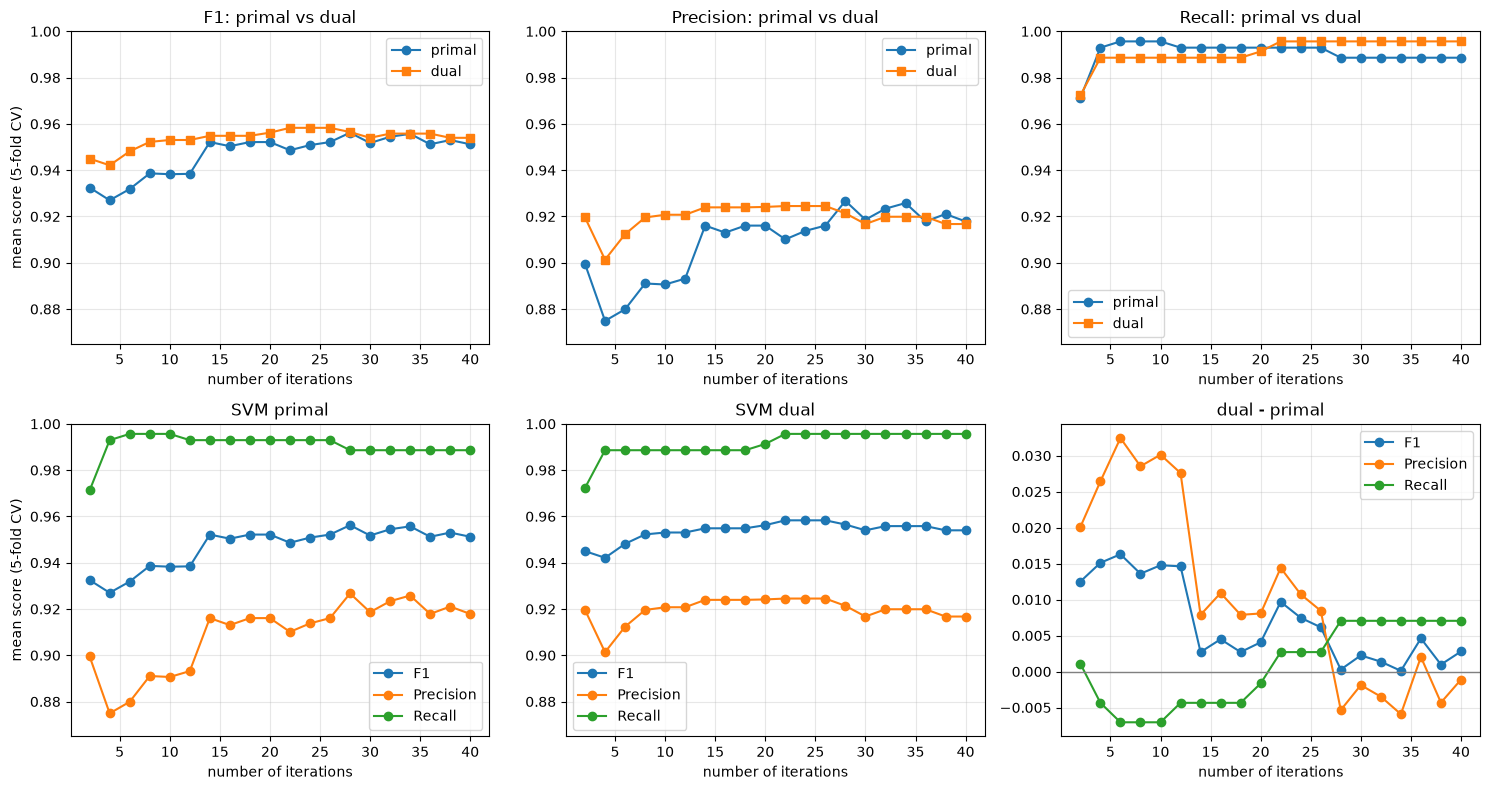

In [7]:
import matplotlib
import matplotlib.pyplot as plt

score_names = ['F1', 'Precision', 'Recall']
method_names = ['primal', 'dual']
method_markers = ['o-', 's-']

fig, axes = plt.subplots(2, nscore, figsize=(15, 8))
ylim = (xmean.min() - 0.01, min(1.0, xmean.max() + 0.01))

# row 1: compare the two methods on each score
for iscore in range(nscore):
    ax = axes[0, iscore]
    for imethod in range(nmethod):
        ax.plot(literations, xmean[imethod, :, iscore], method_markers[imethod],
                label=method_names[imethod])
    ax.set_title(score_names[iscore] + ': primal vs dual')
    ax.set_ylim(ylim)
    ax.set_xlabel('number of iterations')
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0, 0].set_ylabel('mean score (5-fold CV)')

# row 2: all three scores for each method
for imethod in range(nmethod):
    ax = axes[1, imethod]
    for iscore in range(nscore):
        ax.plot(literations, xmean[imethod, :, iscore], 'o-', label=score_names[iscore])
    ax.set_title('SVM ' + method_names[imethod])
    ax.set_ylim(ylim)
    ax.set_xlabel('number of iterations')
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[1, 0].set_ylabel('mean score (5-fold CV)')

# last panel: difference dual - primal for each score
ax = axes[1, 2]
for iscore in range(nscore):
    ax.plot(literations, xmean[1, :, iscore] - xmean[0, :, iscore], 'o-',
            label=score_names[iscore])
ax.axhline(0, color='gray', linewidth=1)
ax.set_title('dual - primal')
ax.set_xlabel('number of iterations')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()